<a href="https://colab.research.google.com/github/matheeshagit/Covertype_Deep_Learning_Solution/blob/main/Covertype.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install ucimlrepo

In [3]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
covertype = fetch_ucirepo(id=31)

# data (as pandas dataframes)
X = covertype.data.features
y = covertype.data.targets

In [4]:
X.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,0
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,0
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,0
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,0
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,0


In [5]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 54 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Elevation                           581012 non-null  int64
 1   Aspect                              581012 non-null  int64
 2   Slope                               581012 non-null  int64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  int64
 4   Vertical_Distance_To_Hydrology      581012 non-null  int64
 5   Horizontal_Distance_To_Roadways     581012 non-null  int64
 6   Hillshade_9am                       581012 non-null  int64
 7   Hillshade_Noon                      581012 non-null  int64
 8   Hillshade_3pm                       581012 non-null  int64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  int64
 10  Wilderness_Area1                    581012 non-null  int64
 11  Soil_Type1                          581012 non-null 

In [6]:
X.shape

(581012, 54)

In [7]:
y.value_counts()

,count
Cover_Type,
2,283301
1,211840
3,35754
7,20510
6,17367
5,9493
4,2747


In [8]:
X.duplicated().sum()

np.int64(0)

In [9]:
X.isnull().sum()

,0
Elevation,0
Aspect,0
Slope,0
Horizontal_Distance_To_Hydrology,0
Vertical_Distance_To_Hydrology,0
Horizontal_Distance_To_Roadways,0
Hillshade_9am,0
Hillshade_Noon,0
Hillshade_3pm,0
Horizontal_Distance_To_Fire_Points,0


## Preprocessing

In [10]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [11]:
#Fix Target Classes
y_array = y.values.ravel() - 1

#Seperate continuous features from binary features
continuous_cols = X.columns[:10]
binary_cols = X.columns[10:]

In [12]:
#Train, validation, test split and Scale continuous features
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_array,
    test_size=0.30,
    random_state=42,
    stratify=y_array
)

scaler = StandardScaler()
X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_temp[continuous_cols] = scaler.transform(X_temp[continuous_cols])

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

In [13]:
print(f"Training set shape:   {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Test set shape:       {X_test.shape}")

Training set shape:   (406708, 54)
Validation set shape: (87152, 54)
Test set shape:       (87152, 54)


## Deep Learning Feedforward Network

In [14]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [17]:
input_shape = [54]

model = keras.Sequential([
    layers.Dense(units=256, activation='relu', input_shape=(X_train.shape[1],)),
    layers.BatchNormalization(),
    layers.Dense(units=128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(units=64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(units=7, activation='softmax'),
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [19]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=512,
    verbose=1
)

Epoch 1/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.8813 - loss: 0.2901 - val_accuracy: 0.8888 - val_loss: 0.2734
Epoch 2/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8921 - loss: 0.2644 - val_accuracy: 0.8949 - val_loss: 0.2591
Epoch 3/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8995 - loss: 0.2469 - val_accuracy: 0.8981 - val_loss: 0.2480
Epoch 4/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9058 - loss: 0.2329 - val_accuracy: 0.9041 - val_loss: 0.2374
Epoch 5/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9097 - loss: 0.2229 - val_accuracy: 0.9059 - val_loss: 0.2328
Epoch 6/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9132 - loss: 0.2132 - val_accuracy: 0.9146 - val_loss: 0.2123
Epoch 7/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9166 - loss: 0.2061 - val_accuracy: 0.9142 - val_loss: 0.2133
Epoch 8/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.9197 - loss: 0.1992 - val_a

<Axes: >

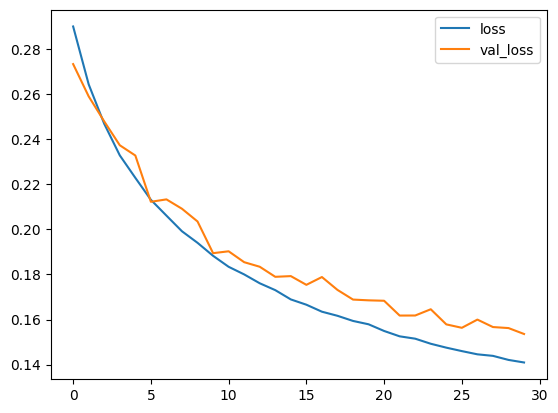

In [20]:
history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot()